In [ ]:
# !pip install gradio

  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---- ----------------------------------- 3.4/31.4 MB 19.3 MB/s eta 0:00:02
   --------- ------------------------------ 7.3/31.4 MB 19.1 MB/s eta 0:00:02
   -------------- ------------------------- 11.3/31.4 MB 19.0 MB/s eta 0:00:02
   ------------------- -------------------- 15.5/31.4 MB 18.9 MB/s eta 0:00:01
   ------------------------ --------------- 19.1/31.4 MB 18.9 MB/s eta 0:00:01
   ----------------------------- ---------- 23.1/31.4 MB 18.8 MB/s eta 0:00:01
   ---------------------------------- ----- 27.3/31.4 MB 18.9 MB/s eta 0:00:01
   ---------------------------------------  31.2/31.4 MB 18.9 MB/s eta 0:00:01
   ---------------------------------------  31.2/31.4 MB 18.9 MB/s eta 0:00:01
   ---------------------------------------  31.2/31.4 MB 18.9 MB/s eta 0:00:01
   ---------------------------------------- 31.4/31.4 MB 14.0 MB/s  0:00:02
   ---

In [6]:
# Import libraries
import pandas as pd                  # Data manipulation and preprocessing
import matplotlib.pyplot as plt      # Data visualization and plotting
import seaborn as sns                # Statistical data visualization
import missingno as msno             # Visualizing missing data
from collections import Counter     # Counting occurrences of elements

# Model Selection
from sklearn.model_selection import train_test_split  # Split data into training and testing sets
from sklearn.model_selection import GridSearchCV      # Find the best model hyperparameters

# Data Preprocessing
from sklearn.compose import ColumnTransformer        # Apply different preprocessing to different columns
from sklearn.pipeline import Pipeline                 # Combine preprocessing and modeling steps
from sklearn.impute import SimpleImputer              # Handle missing values using mean, median or mode
from sklearn.preprocessing import StandardScaler     # Standardize numerical features (mean=0, std=1)
from sklearn.preprocessing import OneHotEncoder      # Convert categorical values into binary columns (0/1)

# Machine Learning Model
from sklearn.ensemble import RandomForestClassifier  # Classification model for predicting categories/classes
# from sklearn.ensemble import RandomForestRegressor # Regression model for predicting numerical values

# Model Evaluation
from sklearn.metrics import classification_report          # Evaluate precision, recall, F1-score and support
from sklearn.metrics import confusion_matrix               # Compare actual vs predicted classes
from sklearn.metrics import ConfusionMatrixDisplay         # Visualize the confusion matrix

# Model Deployment
import gradio as gr                               # Build interactive web interfaces for ML models

# Visualization Settings
sns.set_style("whitegrid")                        # Set Seaborn chart background to a white grid

In [9]:
# Load the data
path = r"files\academic_survival_longitudinal.csv"

df = pd.read_csv(path)

In [8]:
df.head()

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


In [14]:
df.columns # List all clumns

Index(['Student_ID', 'Age', 'Gender', 'First_Generation', 'Family_Income',
       'Household_Size', 'Housing_Status', 'Scholarship', 'Tuition_Base',
       'Semester', 'Course_Load', 'Work_Hours', 'Emergency_Expense', 'Sem_GPA',
       'Attendance', 'LMS_Logins', 'Advising_Visits', 'Failed_Courses',
       'Financial_Stress', 'Target_Dropout_Next_Sem', 'End_of_Semester_Status',
       'Censored'],
      dtype='object')

In [17]:
df.columns = df.columns.str.lower() # save the column names to lower case

df.columns

Index(['student_id', 'age', 'gender', 'first_generation', 'family_income',
       'household_size', 'housing_status', 'scholarship', 'tuition_base',
       'semester', 'course_load', 'work_hours', 'emergency_expense', 'sem_gpa',
       'attendance', 'lms_logins', 'advising_visits', 'failed_courses',
       'financial_stress', 'target_dropout_next_sem', 'end_of_semester_status',
       'censored'],
      dtype='object')

In [18]:
df.shape # data dimension

(79239, 22)

In [13]:
df.describe() # check for correlation

,Age,First_Generation,Family_Income,Household_Size,Scholarship,Tuition_Base,Semester,Course_Load,Work_Hours,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,Censored
count,79239.000000,79239.000000,75635.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,78372.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000
mean,19.492005,0.327894,61518.384346,3.187547,0.277515,24775.110741,3.145673,14.888615,16.936129,200.496788,2.691463,85.081599,66.375670,0.477530,0.652494,2.578287,0.087293,0.140272
std,2.139140,0.469449,39661.166570,1.332861,0.447775,10794.899387,1.946207,2.307308,10.724479,724.400513,0.422692,6.415864,12.730793,0.671954,0.786066,1.817880,0.282266,0.347271
min,17.000000,0.000000,3000.000000,1.000000,0.000000,15000.000000,1.000000,9.000000,0.000000,0.000000,0.440000,-2.000000,12.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,18.000000,0.000000,35000.000000,2.000000,0.000000,15000.000000,1.000000,12.000000,8.300000,0.000000,2.440000,81.200000,58.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,19.000000,0.000000,52000.000000,3.000000,0.000000,25000.000000,3.000000,15.000000,16.500000,0.000000,2.700000,85.200000,66.000000,0.000000,0.000000,2.100000,0.000000,0.000000
75%,21.000000,1.000000,77000.000000,4.000000,1.000000,25000.000000,4.000000,15.000000,24.900000,0.000000,2.960000,89.200000,75.000000,1.000000,1.000000,3.400000,0.000000,0.000000
max,37.000000,1.000000,488000.000000,6.000000,1.000000,45000.000000,8.000000,21.000000,40.000000,3998.000000,3.960000,105.000000,116.000000,3.000000,5.000000,18.600000,1.000000,1.000000


In [20]:
df.info() # data type and missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79239 entries, 0 to 79238
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               79239 non-null  object 
 1   age                      79239 non-null  int64  
 2   gender                   79239 non-null  object 
 3   first_generation         79239 non-null  int64  
 4   family_income            75635 non-null  float64
 5   household_size           79239 non-null  int64  
 6   housing_status           79239 non-null  object 
 7   scholarship              79239 non-null  int64  
 8   tuition_base             79239 non-null  int64  
 9   semester                 79239 non-null  int64  
 10  course_load              79239 non-null  int64  
 11  work_hours               79239 non-null  float64
 12  emergency_expense        79239 non-null  float64
 13  sem_gpa                  79239 non-null  float64
 14  attendance            

In [21]:
df.isna().sum() # check for missing values

student_id                    0
age                           0
gender                        0
first_generation              0
family_income              3604
household_size                0
housing_status                0
scholarship                   0
tuition_base                  0
semester                      0
course_load                   0
work_hours                    0
emergency_expense             0
sem_gpa                       0
attendance                    0
lms_logins                  867
advising_visits               0
failed_courses                0
financial_stress              0
target_dropout_next_sem       0
end_of_semester_status        0
censored                      0
dtype: int64

In [24]:
df.duplicated().sum() # check for duplicates

np.int64(0)

In [26]:
# How many students fall in each administrative status
df["end_of_semester_status"].value_counts()

end_of_semester_status
Enrolled       70354
Dropped_Out     6917
Graduated       1968
Name: count, dtype: int64

In [ ]:
# Target column: This is what we want to predict, so we must exclude it from the input features (X) to prevent data leakage for the model. It will be used as the target variable (y). This column will give the model cheat answer which wont help it make predictions on its own
df["target_dropout_next_sem"].value_counts()

# Identifier columns: Drop unique IDs from input features (X) because they identify records rather than meaningful predictive patterns and may cause the model to learn misleading relationships.

target_dropout_next_sem
0    72322
1     6917
Name: count, dtype: int64

#### Data Quality Check and Handling

In [29]:
print(df['gender'].value_counts(), 'n')
print(df['housing_status'].value_counts(), 'n')

gender
Female               38035
Male                 36556
Other                 1125
female                 875
male                   764
M                      739
F                      716
Prefer not to say      429
Name: count, dtype: int64 n
housing_status
On-Campus       31315
With Parents    24767
Off-Campus      23157
Name: count, dtype: int64 n


In [32]:
# SO may inconsistencies in the gender
# A Mapping dict to fix messy version -> clean version (current state: new state)
gender_map = {
    'f': 'Female', 'female': 'Female',
    'm': 'Male', 'male': 'Male',
}

df['gender'] = (df['gender'].str.strip().str.lower().map(gender_map).fillna(df['gender']))

In [33]:
print(df['gender'].value_counts())

gender
Female               39626
Male                 38059
Other                 1125
Prefer not to say      429
Name: count, dtype: int64


### Separate Features(X) and Target(Y)

In [36]:
# Target Variable -- What to predict
target = 'target_dropout_next_sem'

# columns to be excluded

columns_to_exclude = ['student_id', target, 'end_of_semester_status', 'censored']

# List - all columns excluding those mentioned above
features = [col for col in df.columns if col not in columns_to_exclude]


In [37]:
features

['age',
 'gender',
 'first_generation',
 'family_income',
 'household_size',
 'housing_status',
 'scholarship',
 'tuition_base',
 'semester',
 'course_load',
 'work_hours',
 'emergency_expense',
 'sem_gpa',
 'attendance',
 'lms_logins',
 'advising_visits',
 'failed_courses',
 'financial_stress']

In [43]:
# define x and y variables

X = df[features] # independent variable
y = df[target] # dependent variable - depends on x

### Check the class balance of the target

In [44]:
print(y.value_counts())
print((y.value_counts(normalize=True) * 100).round(2)) # percentage

target_dropout_next_sem
0    72322
1     6917
Name: count, dtype: int64
target_dropout_next_sem
0    91.27
1     8.73
Name: proportion, dtype: float64


### Separate Numerical and Categorical Columns

In [ ]:
# Numerical Col
num_col = X.select_dtypes(include='number').columns.tolist()

# Categorical col
cat_col = X.select_dtypes(exclude='number').columns.tolist()

print('Numerical columns', num_col)
print('Catergorical columsn', cat_col)

Numerical columns ['age', 'first_generation', 'family_income', 'household_size', 'scholarship', 'tuition_base', 'semester', 'course_load', 'work_hours', 'emergency_expense', 'sem_gpa', 'attendance', 'lms_logins', 'advising_visits', 'failed_courses', 'financial_stress']
Catergorical columsn ['gender', 'housing_status']


### Train/Test Split (with stratification)


In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Check sizes: expected approx (63391, 18) and (15848, 18)
print('Train shape:', X_train.shape)
print('Test shape :', X_test.shape)

# Check stratification worked: both should be about 8.7% dropout
print(f'Dropout rate in train: {y_train.mean():.3%}')
print(f'Dropout rate in test : {y_test.mean():.3%}')


Train shape: (63391, 18)
Test shape : (15848, 18)
Dropout rate in train: 8.730%
Dropout rate in test : 8.727%


### Preprocessing Pipeline Constrcution

#### Numerical Transformer

In [50]:
# Mini-pipeline for numerical columns
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Replace missing numerical values with the median
    ('scaler', StandardScaler()),                    # Standardize values to have a mean of 0 and standard deviation of 1
])

#### Categorical Transformer

In [51]:
# Mini-pipeline for categorical columns
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Replace missing categorical values with the most frequent value (mode)
    ('onehot', OneHotEncoder(handle_unknown='ignore')),    # Convert categories into binary (0/1) columns and ignore unseen categories during prediction
])

In [52]:
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_col),
    ('cat', cat_transformer, cat_col)
])

#### Full end-to-end pipeline (preprocessing + model) - Random Forest Classifier

In [53]:
full_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'))
])

# displaying the object as a visual diagram of the pipeline
full_pipeline

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## STEP 3: Model Training & Optimisation

#### Train the baseline model

In [54]:
# Train the entire pipepline in one line
full_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


##### Make predictions on the test set

In [55]:
# Class prediction (0/1) for every student in the test set
y_pred = full_pipeline.predict(X_test)

##### Evaluate the baseline model

In [56]:
# Text report of precision, recall, f1-score
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Dropout (1)']))

              precision    recall  f1-score   support

Retained (0)       0.92      1.00      0.96     14465
 Dropout (1)       0.64      0.06      0.11      1383

    accuracy                           0.92     15848
   macro avg       0.78      0.53      0.53     15848
weighted avg       0.89      0.92      0.88     15848



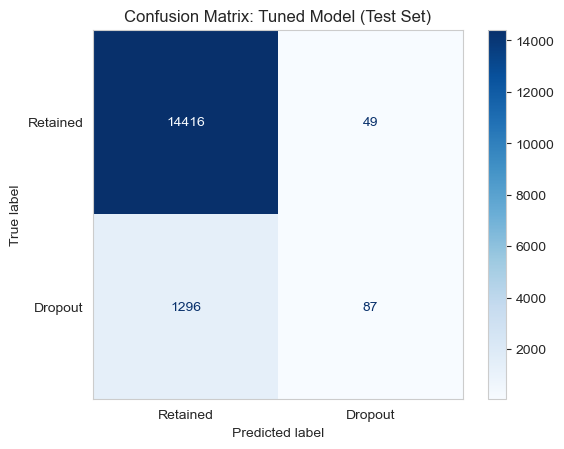

Dropouts correctly flagged (TP): 87
Dropouts missed           (FN): 1296
False alarms              (FP): 49
Correctly left alone      (TN): 14416


In [57]:
# Build the 2x2 matrix from true vs predicted labels
cm = confusion_matrix(y_test, y_pred)

# Plot it nicely with labels
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Retained', 'Dropout'])
disp.plot(cmap='Blues', values_format='d')   # 'd' = show whole numbers
plt.title('Confusion Matrix: Tuned Model (Test Set)')
plt.grid(False)
plt.show()

# Unpack the four numbers for a plain-English summary
tn, fp, fn, tp = cm.ravel()   # .ravel() flattens the 2x2 matrix into 4 values
print(f'Dropouts correctly flagged (TP): {tp}')
print(f'Dropouts missed           (FN): {fn}')
print(f'False alarms              (FP): {fp}')
print(f'Correctly left alone      (TN): {tn}')

#### Feature Importance

In [58]:
# Look at the fitted preprocessor step
full_pipeline.named_steps['preprocessor']

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [59]:
# Drill down to the fitted OneHotEncoder and ask for its output column names
ohe_feature_names = (full_pipeline.named_steps['preprocessor']
                     .named_transformers_['cat']
                     .named_steps['onehot']
                     .get_feature_names_out(cat_col))

# The ColumnTransformer outputs numeric columns FIRST, then categorical ones,
# so we join the names in that same order
all_feature_names = num_col + list(ohe_feature_names)

print(f'Total features the model sees: {len(all_feature_names)}')
all_feature_names

Total features the model sees: 23


['age',
 'first_generation',
 'family_income',
 'household_size',
 'scholarship',
 'tuition_base',
 'semester',
 'course_load',
 'work_hours',
 'emergency_expense',
 'sem_gpa',
 'attendance',
 'lms_logins',
 'advising_visits',
 'failed_courses',
 'financial_stress',
 'gender_Female',
 'gender_Male',
 'gender_Other',
 'gender_Prefer not to say',
 'housing_status_Off-Campus',
 'housing_status_On-Campus',
 'housing_status_With Parents']

In [60]:
# Grab the trained model (last step of the pipeline)
model = full_pipeline.named_steps['classifier']

# hasattr() checks whether the object has that attribute
if hasattr(model, 'feature_importances_'):
    importances = model.feature_importances_          # tree models
else:
    importances = np.abs(model.coef_[0])              # logistic regression: size of each coefficient

# Put names and scores side by side in a DataFrame, sorted from most to least important
fi_df = (pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
         .sort_values(by='Importance', ascending=False)
         .reset_index(drop=True))

fi_df.head(10)

,Feature,Importance
0,sem_gpa,0.163033
1,financial_stress,0.104833
2,work_hours,0.096701
3,attendance,0.093469
4,family_income,0.089817
5,lms_logins,0.078517
6,failed_courses,0.063253
7,age,0.046122
8,semester,0.041814
9,household_size,0.037027


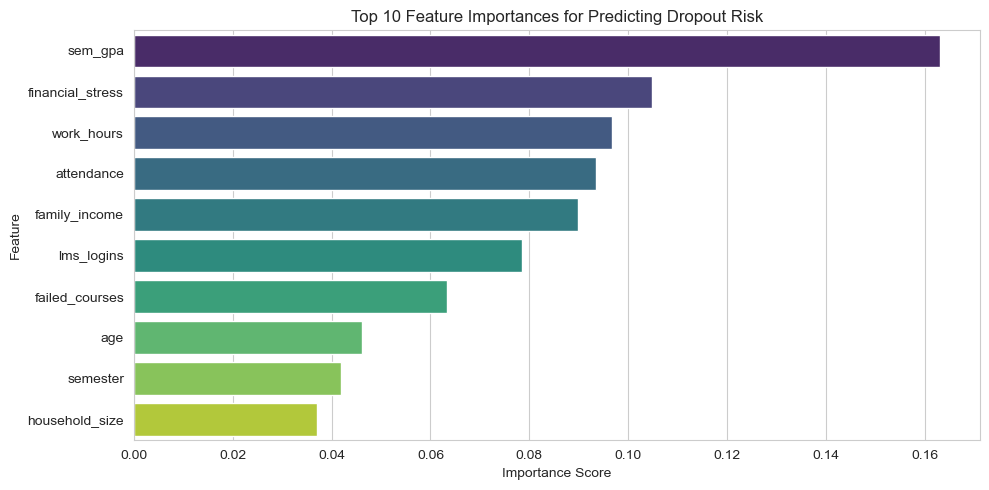

In [63]:
# Plot the Top 10 most important features
plt.figure(figsize=(10, 5))

# hue='Feature' + legend=False is the modern way to colour bars with a palette
# (the older `palette=` alone triggers a FutureWarning in recent seaborn versions)
sns.barplot(data=fi_df.head(10), x='Importance', y='Feature',
            hue='Feature', palette='viridis', legend=False)

plt.title('Top 10 Feature Importances for Predicting Dropout Risk')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()    # stops labels from being cut off
plt.show()